# NYC Food Safety Inspection Model
*Predicting serious health-inspection failures in NYC restaurants*

## Part 4: Interpretation and Recommendations

The model selected in [Notebook 3](03_model_comparison.ipynb) is only useful if people can trust it and act on it. This notebook answers four questions:
1. **What drives the model's risk scores?** (grouped permutation importance)
2. **Are the main risk factors statistically reliable, and how large are they?** (logistic regression with confidence intervals)
3. **What would the model change in practice?** (risk tiers and inspections saved)
4. **What should the Health Department do?** (recommendations)

## 1. Setup

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from sklearn.metrics import average_precision_score

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.float_format", "{:,.3f}".format)

PROCESSED_PATH = Path("../data/processed/model_table.csv.gz")
MODELS_DIR = Path("../models")
IMAGES_DIR = Path("../images")
RANDOM_STATE = 42
CAPACITY = 0.20
FAIL_COLOR, PASS_COLOR, GRAY = "#c0392b", "#2e86c1", "#7f8c8d"


def save_fig(fig, name):
    """Save a figure to images/ so the README can show it."""
    fig.savefig(IMAGES_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

## 2. Load the final model and the test period

In [2]:
# Load the fitted pipeline and its settings saved by Notebook 3
model = joblib.load(MODELS_DIR / "best_model.joblib")
info = json.loads((MODELS_DIR / "best_model_info.json").read_text())
FEATURES = info["numeric_features"] + info["categorical_features"]

model_df = pd.read_csv(PROCESSED_PATH, parse_dates=["inspection_date"]).sort_values("inspection_date").reset_index(drop=True)
model_df["inspection_month"] = model_df["inspection_month"].astype(str)
# Recreate exactly the same train/test split as Notebook 3
is_train = model_df["inspection_date"] < pd.Timestamp(info["train_cutoff_date"])
train, test = model_df[is_train].copy(), model_df[~is_train].copy()
test["risk_score"] = model.predict_proba(test[FEATURES])[:, 1]

print(f"Final model: {info['model']} with {info['best_hyperparameters']}")
print(f"Test period: {len(test):,} inspections, PR-AUC {average_precision_score(test['fail'], test['risk_score']):.3f}")

Final model: Logistic regression with {'C': 0.01, 'class_weight': None}
Test period: 9,226 inspections, PR-AUC 0.357


## 3. What drives the risk scores? Grouped permutation importance

**Method:** shuffle one group of related features at a time in the test data, re-score, and measure how much PR-AUC drops. A big drop means the model relies heavily on that group. Related features are shuffled **together** (for example, all past-score features), because shuffling one of several overlapping features alone would understate their shared importance. Each group is shuffled 10 times to show the variation.

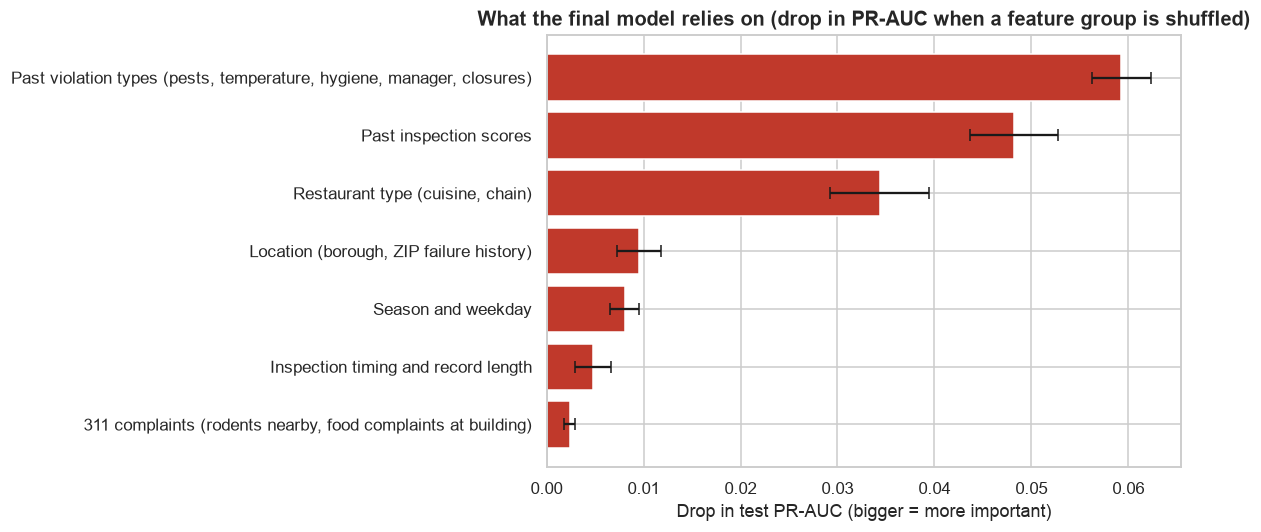

,mean,std
group,,
"Past violation types (pests, temperature, hygiene, manager, closures)",0.059,0.003
Past inspection scores,0.048,0.005
"Restaurant type (cuisine, chain)",0.034,0.005
"Location (borough, ZIP failure history)",0.010,0.002
Season and weekday,0.008,0.002
Inspection timing and record length,0.005,0.002
"311 complaints (rodents nearby, food complaints at building)",0.002,0.001


In [3]:
FEATURE_GROUPS = {
    "Past inspection scores": ["prev_cycle_score", "prev_cycle_fail", "last_score", "prior_mean_score", "score_trend"],
    "Past violation types (pests, temperature, hygiene, manager, closures)": [
        "last_n_critical", "last_had_pest", "prior_pest_visits", "prior_temperature_visits", "prior_hygiene_visits",
        "prior_no_fpc_visits", "prior_closed_visits"],
    "Inspection timing and record length": ["days_since_prev_cycle", "n_prior_inspections", "days_since_last_inspection",
                                            "has_prior_inspection"],
    "Restaurant type (cuisine, chain)": ["cuisine_group", "chain_size", "is_chain"],
    "Location (borough, ZIP failure history)": ["boro", "zip_prior_fail_rate"],
    "311 complaints (rodents nearby, food complaints at building)": ["rodent_complaints_zip_3m", "food_complaints_bbl_12m"],
    "Season and weekday": ["inspection_month", "inspection_dow"],
}
assert sorted(sum(FEATURE_GROUPS.values(), [])) == sorted(FEATURES), "every feature must be in exactly one group"

# Fixed random seed so the shuffles (and the importance values) are reproducible
rng = np.random.default_rng(RANDOM_STATE)
base_pr_auc = average_precision_score(test["fail"], test["risk_score"])
importance_rows = []
for group, cols in FEATURE_GROUPS.items():
    for repeat in range(10):
        shuffled = test[FEATURES].copy()
        order = rng.permutation(len(shuffled))
        shuffled[cols] = shuffled[cols].to_numpy()[order]  # shuffle the group's rows together
        drop = base_pr_auc - average_precision_score(test["fail"], model.predict_proba(shuffled)[:, 1])
        importance_rows.append({"group": group, "drop in PR-AUC": drop})
importance = (pd.DataFrame(importance_rows).groupby("group")["drop in PR-AUC"]
              .agg(["mean", "std"]).sort_values("mean"))

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(importance.index, importance["mean"], xerr=importance["std"], color=FAIL_COLOR, capsize=4)
ax.set(title="What the final model relies on (drop in PR-AUC when a feature group is shuffled)",
       xlabel="Drop in test PR-AUC (bigger = more important)")
plt.tight_layout()
save_fig(fig, "feature_importance")
plt.show()
importance.sort_values("mean", ascending=False)

**Observations:**
* The model relies most on a restaurant's **own track record**: the *types* of earlier violations (pests, temperature, hygiene, missing certified manager, closures; PR-AUC drop 0.059) and its **earlier scores** (0.048).
* **Restaurant type** (cuisine and chain status) is the third pillar (0.034).
* Location, season and inspection timing add smaller amounts (0.005–0.010), and **311 complaints barely matter** to the model (0.002), consistent with the feature test in Notebook 3.
* In plain terms: *how a restaurant has behaved before, and what kind of kitchen it runs, tell you most about how it will do next time.*

## 4. How does risk change with the key factors?

The charts below show the model's **average predicted risk** on the test period for different values of the most important factors, next to the **actual** failure rate. Matching bars mean the model has learned the real pattern.

Previous routine score | actual: A range: 15%, B range: 25%, C range: 30%, 42+: 39%, No earlier
routine visit: 24% | predicted: 12%, 18%, 26%, 33%, 22%
Earlier visits with pests | actual: 0: 17%, 1: 22%, 2+: 33% | predicted: 14%, 19%, 27%
Chain status | actual: Chain (5+ locations): 12%, Independent: 24% | predicted: 9%, 20%
Average predicted risk 17.7% vs actual failure rate 21.3%


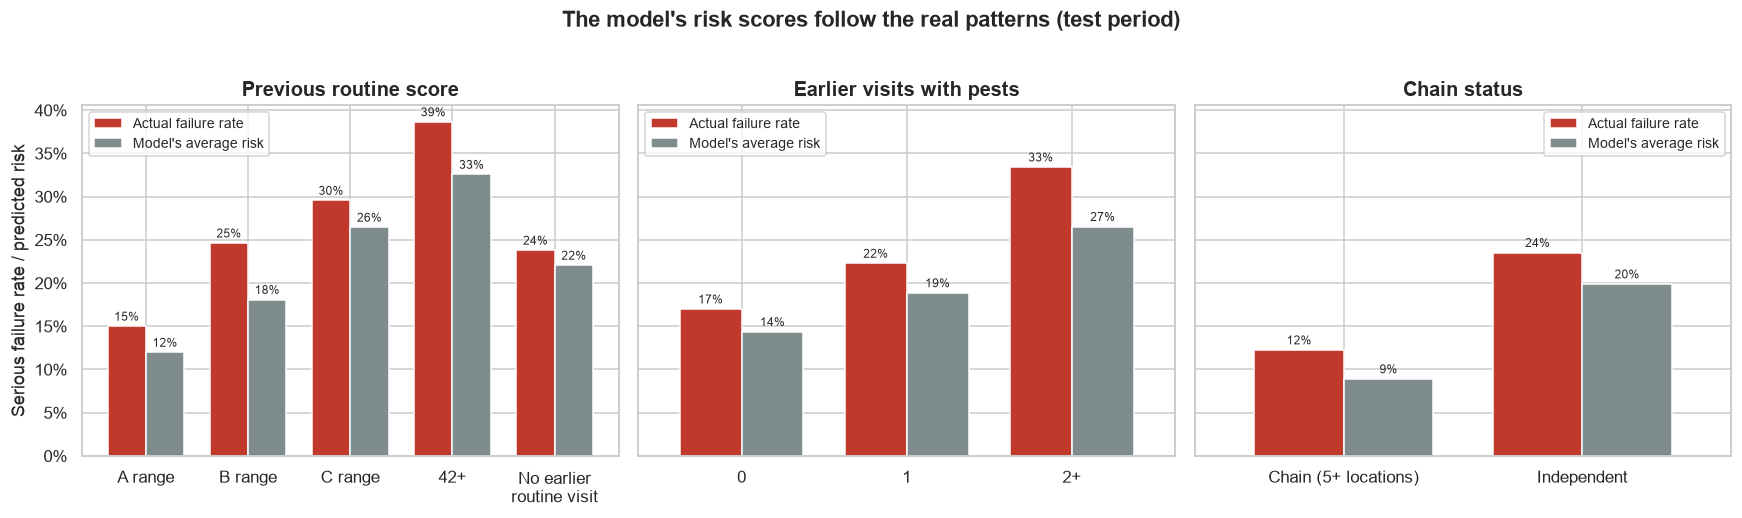

In [4]:
# Group test inspections into readable bands for three key factors
panels = test.copy()
panels["Previous routine score"] = pd.cut(panels["prev_cycle_score"], [-1, 13, 27, 41, 1000],
                                          labels=["A range", "B range", "C range", "42+"]).cat.add_categories("No earlier\nroutine visit")
panels["Previous routine score"] = panels["Previous routine score"].fillna("No earlier\nroutine visit")
panels["Earlier visits with pests"] = pd.cut(panels["prior_pest_visits"], [-1, 0, 1, 100], labels=["0", "1", "2+"])
panels["Chain status"] = np.where(panels["is_chain"] == 1, "Chain (5+ locations)", "Independent")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, col in zip(axes, ["Previous routine score", "Earlier visits with pests", "Chain status"]):
    summary = panels.groupby(col, observed=True).agg(actual=("fail", "mean"), predicted=("risk_score", "mean"))
    summary.plot.bar(ax=ax, color=[FAIL_COLOR, GRAY], width=0.75, rot=0)
    for container in ax.containers:
        ax.bar_label(container, labels=[f"{v:.0%}" for v in container.datavalues], fontsize=8, padding=2)
    print(col.replace("\n", " "), "| actual:", ", ".join(f"{i}: {a:.0%}" for i, a in summary["actual"].items()),
          "| predicted:", ", ".join(f"{p:.0%}" for p in summary["predicted"]))
    ax.set(title=col, xlabel="")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.legend(["Actual failure rate", "Model's average risk"], fontsize=9)
axes[0].set_ylabel("Serious failure rate / predicted risk")
fig.suptitle("The model's risk scores follow the real patterns (test period)", fontweight="bold", y=1.02)
print(f"Average predicted risk {test['risk_score'].mean():.1%} vs actual failure rate {test['fail'].mean():.1%}")
plt.tight_layout()
plt.show()

**Observations:**
* Risk rises steadily with the previous routine score: actual failure rates go from **15%** (A range) to **39%** (42+ points), and the model's average risk follows the same staircase (12% to 33%).
* Restaurants with **two or more earlier pest visits** fail **33%** of the time vs **17%** with none; chains fail **12%** of the time vs **24%** for independents. The model reproduces both gaps.
* The model's risk scores run a few points **below** the actual rates everywhere (average 18% predicted vs 21% actual). Failures became more common in 2026 than in the training years, so the *ranking* is right but the *level* is a little low. This matters only if the scores are read as exact probabilities, and it is a reason to retrain regularly (see recommendations).

## 5. Inferential statistics: how big and how certain are the main effects?

Machine-learning models rank well but do not report uncertainty. To give decision-makers **effect sizes with confidence intervals**, I fit a classic logistic regression (`statsmodels`) on the **training period** with a small set of interpretable factors. Each **odds ratio** says how the odds of a serious failure change, holding the other factors constant; the **95% confidence interval** gives the range of plausible values, and the **p-value** tests whether the effect could be zero.

Only restaurants with at least one earlier routine inspection are used, so every factor is defined. The same restaurant can appear several times, and its inspections are not independent, so standard errors are **clustered by restaurant**, which widens the confidence intervals to an honest size. Scores and rates are rescaled so the odds ratios are easy to read (per 10 points, per 5 percentage points).

In [5]:
# Training period only, and only restaurants with an earlier routine score
infer = train[train["prev_cycle_score"].notna()].copy()
infer["Previous routine score (per 10 points)"] = infer["prev_cycle_score"] / 10
infer["Earlier visits with pests (each)"] = infer["prior_pest_visits"]
infer["Earlier closures (each)"] = infer["prior_closed_visits"]
infer["Chain with 5+ locations"] = infer["is_chain"]
infer["ZIP failure history (per 5 points)"] = infer["zip_prior_fail_rate"] * 100 / 5
infer["311 food complaints at building (each, last year)"] = infer["food_complaints_bbl_12m"]
infer["Summer inspection (Jun-Aug)"] = infer["inspection_month"].isin(["6", "7", "8"]).astype(int)
predictors = ["Previous routine score (per 10 points)", "Earlier visits with pests (each)", "Earlier closures (each)",
              "Chain with 5+ locations", "ZIP failure history (per 5 points)",
              "311 food complaints at building (each, last year)", "Summer inspection (Jun-Aug)"]
infer = infer.dropna(subset=predictors)

# Classic logistic regression: odds ratio = exp(coefficient); CI from the coefficient standard errors
logit = sm.Logit(infer["fail"], sm.add_constant(infer[predictors].astype(float))).fit(
    disp=False, cov_type="cluster", cov_kwds={"groups": infer["camis"]})
odds_table = pd.DataFrame({"odds ratio": np.exp(logit.params), "95% CI low": np.exp(logit.conf_int()[0]),
                           "95% CI high": np.exp(logit.conf_int()[1]), "p-value": logit.pvalues}).drop(index="const")
print(f"Fitted on {int(logit.nobs):,} training inspections; pseudo R² = {logit.prsquared:.3f}")
odds_table.style.format({"odds ratio": "{:.2f}", "95% CI low": "{:.2f}", "95% CI high": "{:.2f}", "p-value": "{:.1e}"})

Fitted on 16,219 training inspections; pseudo R² = 0.070


,odds ratio,95% CI low,95% CI high,p-value
Previous routine score (per 10 points),1.32,1.27,1.36,2.5e-56
Earlier visits with pests (each),1.21,1.15,1.26,6.4e-16
Earlier closures (each),0.73,0.61,0.87,4.9e-04
Chain with 5+ locations,0.45,0.40,0.51,1.0e-35
ZIP failure history (per 5 points),1.18,1.13,1.24,9.7e-13
"311 food complaints at building (each, last year)",1.04,1.02,1.07,5.0e-05
Summer inspection (Jun-Aug),1.50,1.35,1.67,1.7e-14


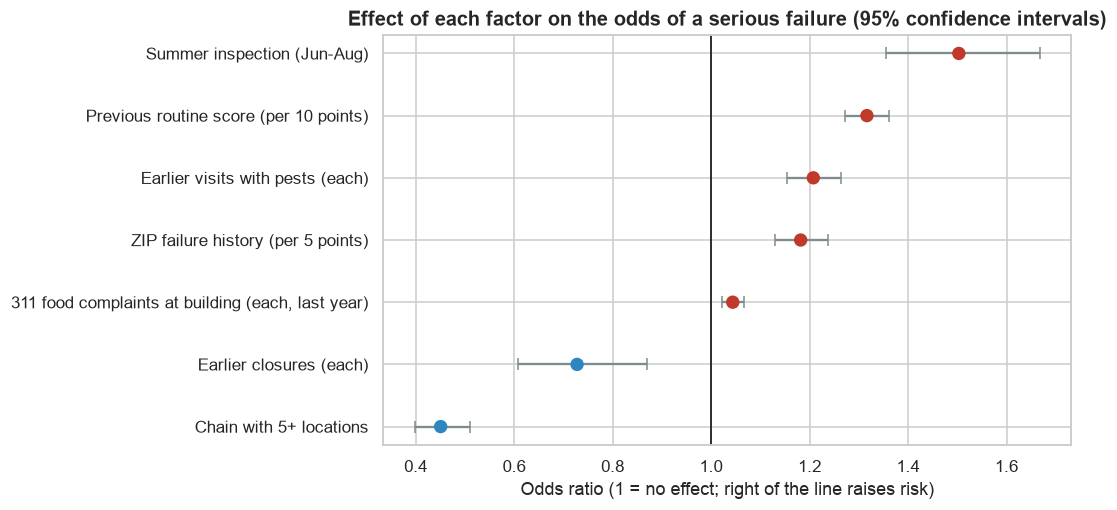

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ordered = odds_table.sort_values("odds ratio")
colors = [FAIL_COLOR if v > 1 else PASS_COLOR for v in ordered["odds ratio"]]
ax.errorbar(ordered["odds ratio"], ordered.index,
            xerr=[ordered["odds ratio"] - ordered["95% CI low"], ordered["95% CI high"] - ordered["odds ratio"]],
            fmt="none", ecolor=GRAY, capsize=4)
ax.scatter(ordered["odds ratio"], ordered.index, color=colors, s=60, zorder=3)
ax.axvline(1, color="black", lw=1)
ax.set(title="Effect of each factor on the odds of a serious failure (95% confidence intervals)",
       xlabel="Odds ratio (1 = no effect; right of the line raises risk)")
plt.tight_layout()
save_fig(fig, "odds_ratios_with_ci")
plt.show()

**Interpretation** (all effects significant at p < 0.001 with restaurant-clustered standard errors; every confidence interval excludes 1):
* **Previous routine score:** every 10 extra points on the last routine inspection raises the odds of a serious failure by about **32%** (95% CI 27–36%).
* **Pests:** each earlier visit with pests raises the odds by about **21%** (15–26%).
* **Summer:** inspections in June to August carry **50% higher odds** (35–67%), consistent with heat making safe food temperatures harder to maintain.
* **Neighborhood:** every 5 percentage points of earlier failures in the ZIP code raises the odds by **18%** (13–24%).
* **Building complaints:** each 311 food complaint at the building in the past year adds about **4%** (2–7%), a small but real effect.
* **Chains** have **55% lower odds** of a serious failure (odds ratio 0.45, CI 0.40–0.51), the largest protective factor.
* **Earlier closures** have an odds ratio *below* 1 (0.73, CI 0.61–0.87) once past scores and pests are held constant, although closed restaurants fail more often overall (Notebook 1). A likely reading: a closure forces repairs and brings close follow-up, so among restaurants with *equally bad* records, those that were closed and reopened tend to do slightly better next time. This is a correlation, not proof of cause.

The model explains only part of the variation (pseudo R² = 0.07): inspection results depend a lot on the day itself. That is why the right use of the model is **prioritization**, not prediction of individual outcomes.

## 6. Risk tiers: what the scores mean in practice

Test-period inspections are sorted by risk score and split into ten equal groups (deciles). If the model works, the actual failure rate should climb steadily from the lowest-risk to the highest-risk group.

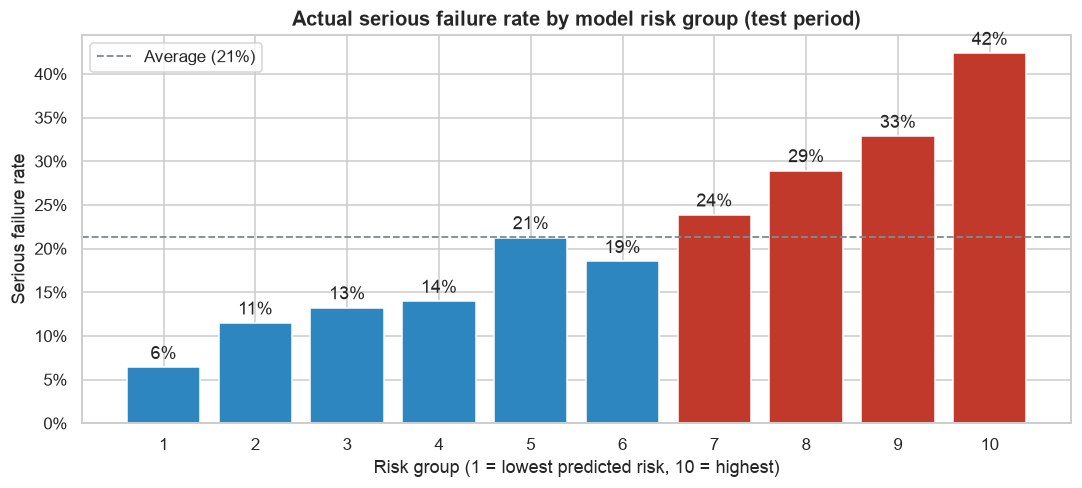

In [7]:
# Ten equal-sized risk groups (rank first so ties are split evenly)
test["risk_decile"] = pd.qcut(test["risk_score"].rank(method="first"), 10, labels=range(1, 11))
deciles = test.groupby("risk_decile", observed=True).agg(inspections=("fail", "size"), failure_rate=("fail", "mean"))

fig, ax = plt.subplots(figsize=(10, 4.6))
bars = ax.bar(deciles.index.astype(str), deciles["failure_rate"],
              color=[FAIL_COLOR if r > test["fail"].mean() else PASS_COLOR for r in deciles["failure_rate"]])
ax.bar_label(bars, labels=[f"{r:.0%}" for r in deciles["failure_rate"]], padding=3)
ax.axhline(test["fail"].mean(), color=GRAY, ls="--", lw=1.2, label=f"Average ({test['fail'].mean():.0%})")
ax.set(title="Actual serious failure rate by model risk group (test period)",
       xlabel="Risk group (1 = lowest predicted risk, 10 = highest)", ylabel="Serious failure rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend()
plt.tight_layout()
save_fig(fig, "risk_deciles")
plt.show()

**Observations:** the failure rate climbs from **7%** in the lowest-risk group to **42%** in the highest-risk group, six times higher. The top three groups (the riskiest 30%) all fail more often than average, while the bottom four groups fail at only 7–14%, well below the 21% average. The model separates restaurants into meaningfully different risk tiers, even though individual outcomes remain uncertain.

## 7. Impact: what changes if inspectors follow the model?

**This is a retrospective simulation.** The test period contains only inspections the city actually carried out, on the dates it chose. The comparison asks: *among those inspections, which ranking would have put the serious failures at the top?* It does not prove how many failures a real re-scheduling would find, because moving an inspection changes its date (and so its season and time-since-last-visit). It is still the fairest estimate available from public data; a live pilot is the way to confirm it.

Compare three ways to choose which 20% of restaurants to visit first in the test period:
* **Random order** (no prioritization),
* **Rule of thumb**: restaurants with the worst previous routine score first (close to current practice),
* **Final model**.

In [8]:
def failures_found(scores, share=CAPACITY):
    """Number of serious failures among the top `share` of inspections ranked by score."""
    k = int(round(len(scores) * share))
    order = np.argsort(-np.asarray(scores), kind="stable")
    return int(test["fail"].to_numpy()[order[:k]].sum()), k


# Three ways to rank the same test inspections
# Random order is averaged over 200 shuffles so it reflects the expected result, not one lucky draw
random_found = np.mean([failures_found(rng.random(len(test)))[0] for _ in range(200)])
strategies = {
              "Rule of thumb (previous score)": test["prev_cycle_score"].fillna(-1).to_numpy(),
              f"Final model ({info['model']})": test["risk_score"].to_numpy()}
impact = pd.DataFrame([{"strategy": "Random order (average of 200 shuffles)", "visits": failures_found(test["risk_score"])[1],
                        "serious failures found": random_found}]
                      + [{"strategy": name, "visits": failures_found(s)[1], "serious failures found": failures_found(s)[0]}
                         for name, s in strategies.items()]).set_index("strategy")
impact["hit rate"] = impact["serious failures found"] / impact["visits"]
impact["share of all failures found"] = impact["serious failures found"] / test["fail"].sum()
impact["failures found per 1,000 visits"] = impact["hit rate"] * 1000
impact.style.format({"serious failures found": "{:,.0f}", "hit rate": "{:.0%}", "share of all failures found": "{:.0%}", "failures found per 1,000 visits": "{:.0f}"})

,visits,serious failures found,hit rate,share of all failures found,"failures found per 1,000 visits"
strategy,,,,,
Random order (average of 200 shuffles),1845,392,21%,20%,213
Rule of thumb (previous score),1845,564,31%,29%,306
Final model (Logistic regression),1845,694,38%,35%,376


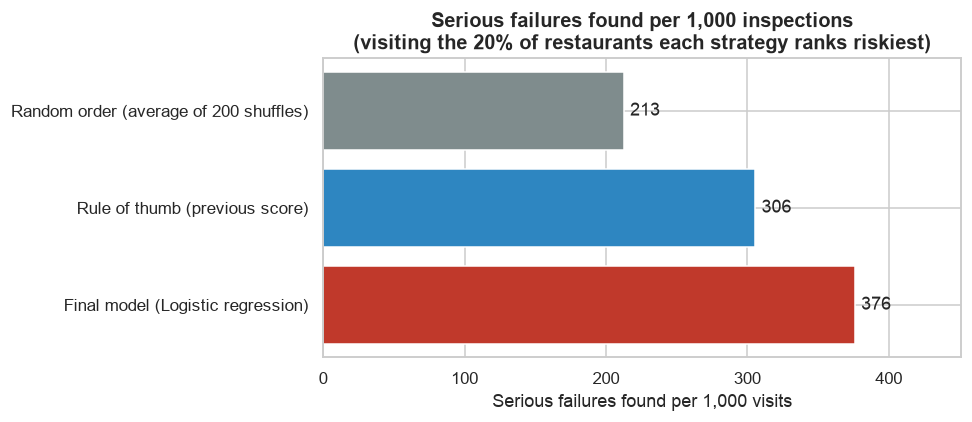

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(impact.index, impact["failures found per 1,000 visits"], color=[GRAY, PASS_COLOR, FAIL_COLOR])
ax.bar_label(bars, labels=[f"{v:.0f}" for v in impact["failures found per 1,000 visits"]], padding=4)
ax.set(title=f"Serious failures found per 1,000 inspections\n(visiting the {CAPACITY:.0%} of restaurants each strategy ranks riskiest)",
       xlabel="Serious failures found per 1,000 visits")
ax.set_xlim(0, impact["failures found per 1,000 visits"].max() * 1.2)
ax.invert_yaxis()
plt.tight_layout()
save_fig(fig, "impact_per_1000_visits")
plt.show()

**Observations:** with the same 1,845 visits (20% of test-period inspections):
* **Random order** finds about **392** serious failures on average (213 per 1,000 visits).
* The **rule of thumb** of visiting the worst previous scores first finds **564** (306 per 1,000).
* The **final model** finds **694** (376 per 1,000): **130 more serious failures than the rule of thumb** (+23%) and about **300 more than random**, with no extra inspectors.

As explained above, this is a retrospective ranking of inspections that actually happened, so the exact gain in a live rollout could differ; the direction and rough size are what matter.

## 8. Example restaurants: why the model flags them

Three anonymized test-period inspections (restaurant names removed) illustrate how the risk score reflects each restaurant's situation.

In [10]:
example_cols = {"risk_score": "Risk score", "fail": "Actually failed?", "cuisine_group": "Cuisine", "boro": "Borough",
                "prev_cycle_score": "Previous routine score", "prior_pest_visits": "Earlier visits with pests",
                "prior_closed_visits": "Earlier closures", "chain_size": "Locations with same name",
                "zip_prior_fail_rate": "ZIP failure history", "food_complaints_bbl_12m": "311 food complaints (last year)"}
# Highest-risk, median-risk and lowest-risk inspections (no restaurant names shown)
examples = pd.concat([test.nlargest(1, "risk_score"),
                      test.iloc[[(test["risk_score"] - test["risk_score"].median()).abs().argmin()]],
                      test.nsmallest(1, "risk_score")])
examples = examples[list(example_cols)].rename(columns=example_cols)
examples.index = ["Highest-risk inspection", "Typical inspection", "Lowest-risk inspection"]
examples["Actually failed?"] = examples["Actually failed?"].map({1: "Yes", 0: "No"})
examples.T

,Highest-risk inspection,Typical inspection,Lowest-risk inspection
Risk score,0.772,0.156,0.011
Actually failed?,No,No,No
Cuisine,Other,Other,Donuts
Borough,Queens,Manhattan,Manhattan
Previous routine score,57.000,NaN,12.000
Earlier visits with pests,5,0,1
Earlier closures,0,0,0
Locations with same name,3,1,333
ZIP failure history,0.247,0.151,0.058
311 food complaints (last year),1.000,0.000,5.000


**Reading the examples:**
* The **highest-risk** inspection (risk 77%) is a small, three-location restaurant in Queens whose previous routine score was 57 points, with pests found on five earlier visits and a ZIP code with a 25% earlier failure rate. **It passed this time.** This is exactly why the model is a prioritization tool: a high score means "check here first", not "this restaurant will fail".
* The **typical** inspection (risk 16%) is an independent restaurant in Manhattan with no earlier routine inspection and no pest history. It passed.
* The **lowest-risk** inspection (risk 1%) is a donut shop belonging to a 333-location chain in a ZIP code with very few failures. It passed. It had one earlier pest visit and five building complaints: no single factor decides the score; the model weighs them together.

## 9. Findings and recommendations

### Key findings
1. **Past behavior predicts future behavior.** A restaurant's earlier scores and the types of violations it has had (especially pests and food-temperature problems) are the strongest warning signs.
2. **Independent restaurants and certain cuisines carry more risk.** Chains have less than half the odds of a serious failure; cuisines that likely involve more complex food handling (Caribbean, Latin American, Chinese) fail more often than counter-service formats (donuts, hamburgers, coffee).
3. **Summer is the riskiest season** (50% higher odds in June to August).
4. **Neighborhood and 311 complaints help only a little** beyond the restaurant's own record.
5. **A simple, explainable model is enough.** Random forest and gradient boosting did not beat a tuned logistic regression.
6. **In a retrospective test, the model ranks 23% more serious failures into the top 20% than the current-style rule of thumb**, with the same number of inspections.

### Recommendations for the Health Department
* **Pilot a monthly risk ranking**: send inspectors to the top of the list first, within the existing inspection cycle, and measure the serious failures found against business as usual.
* **Inspect high-risk restaurants before the summer.** Schedule risky independents with pest or temperature history in spring, ahead of the June-to-August peak.
* **Target outreach to repeat pest offenders.** Offer pest-control guidance or earlier follow-ups to restaurants with two or more earlier pest visits.
* **Explain the ranking.** Because the model is a logistic regression, each restaurant's score can be traced to concrete reasons (for example, "two earlier pest violations, summer inspection"), which supports fairness and transparency.
* **Retrain at least quarterly and monitor.** Failure rates rose in 2026, which pushed the model's risk levels slightly low; regular retraining keeps the ranking and the levels current.

### Next steps
* Pilot the ranking for a few months in one borough and compare failures found against business as usual.
* Test richer data the city holds but does not publish (inspector notes, complaint details, ownership changes) and better time-aware features.
* Check fairness: confirm the ranking does not unfairly target restaurants by cuisine or neighborhood beyond what their own records justify, for example by comparing hit rates across groups.